In [4]:
import sys
from pathlib import Path

DIR_ROOT = Path.cwd().parent.parent
sys.path.insert(0, str(DIR_ROOT))

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from huggingface_hub import logging as hf_logging

# The dataset is public; hide the unauthenticated-request warning.
hf_logging.set_verbosity_error()

import data

listings = data.load("listings")

## Time Series of Sold Price
Market trend and seasonality matter because we train on the past and predict the future.

               date_listed            date_sold external_avm_estimate_date
min    2020-02-19 00:00:00  2021-01-01 00:00:00        2020-12-03 00:00:00
max    2026-05-29 00:00:00  2026-05-31 00:00:00        2027-06-30 00:00:00
count               150000               150000                     150000


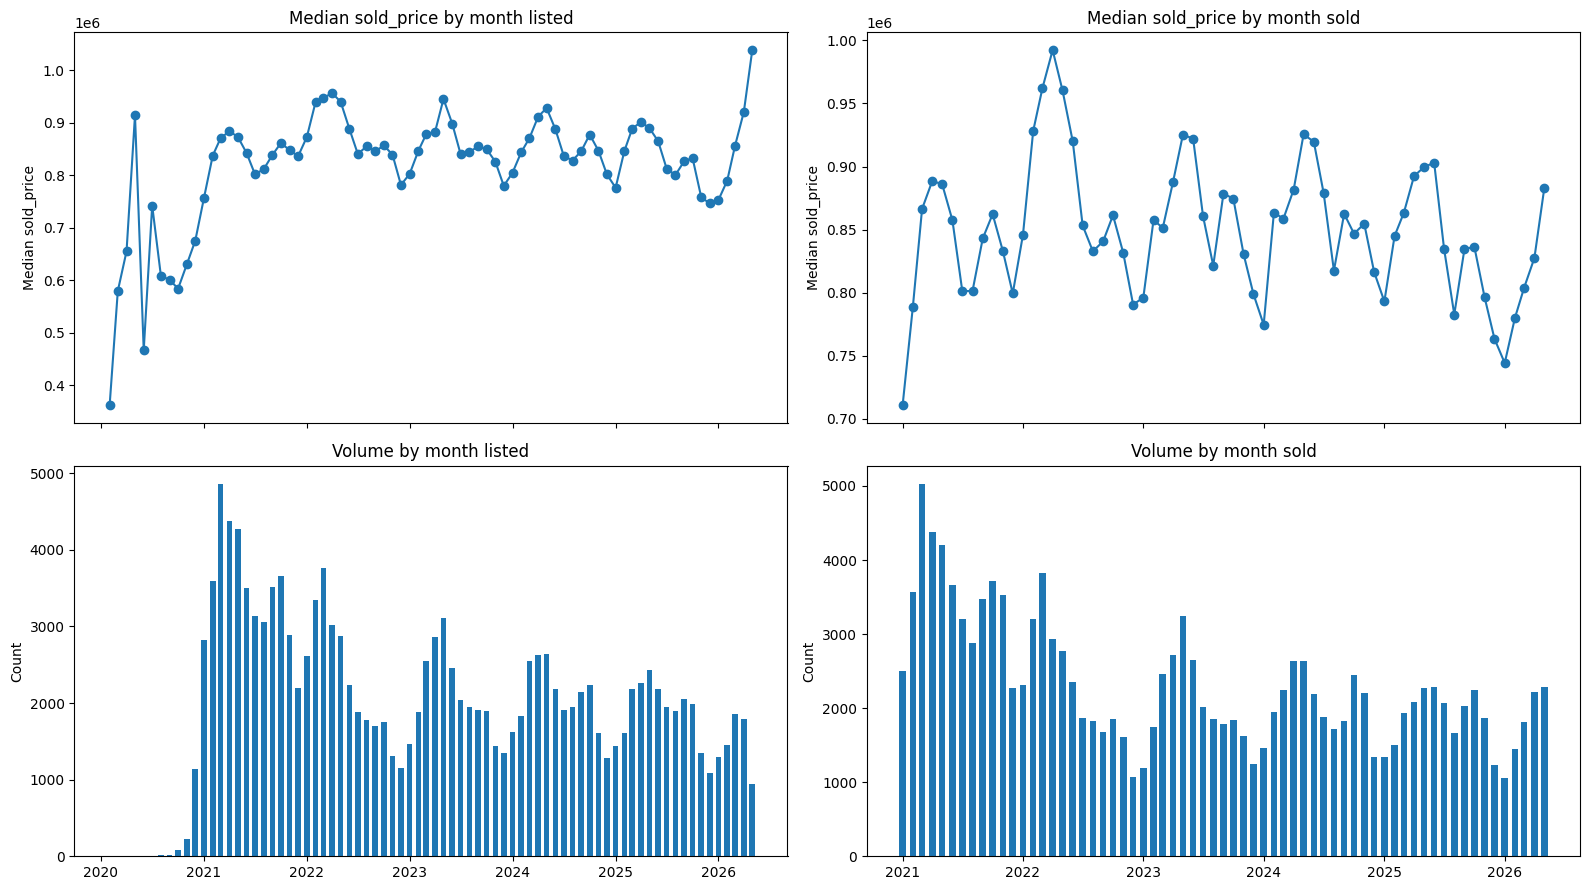

In [5]:
date_cols = ["date_listed", "date_sold", "external_avm_estimate_date"]
for c in date_cols:
    listings[c] = pd.to_datetime(listings[c], errors="coerce")

print(listings[date_cols].agg(["min", "max", "count"]))

# Monthly median price and volume by listing date and by sale date
fig, axes = plt.subplots(2, 2, figsize=(16, 9), sharex="col")
for col, label in [("date_listed", "listed"), ("date_sold", "sold")]:
    j = 0 if col == "date_listed" else 1
    monthly = (
        listings.dropna(subset=[col, "sold_price"])
        .set_index(col)["sold_price"]
        .resample("MS")
        .agg(["median", "count"])
    )
    axes[0, j].plot(monthly.index, monthly["median"], marker="o")
    axes[0, j].set_title(f"Median sold_price by month {label}")
    axes[0, j].set_ylabel("Median sold_price")
    axes[1, j].bar(monthly.index, monthly["count"], width=20)
    axes[1, j].set_title(f"Volume by month {label}")
    axes[1, j].set_ylabel("Count")
plt.tight_layout()
plt.show()

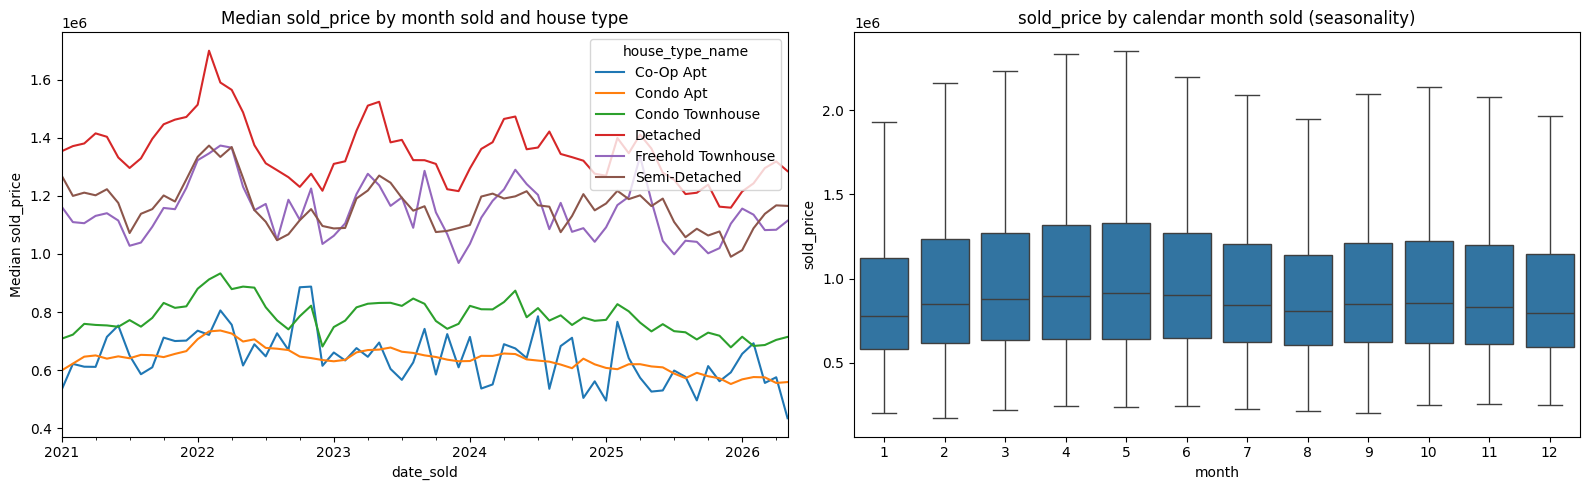

In [6]:
# Median price by house type over time, and seasonality by calendar month
monthly_type = (
    listings.dropna(subset=["date_sold", "sold_price"])
    .groupby([pd.Grouper(key="date_sold", freq="MS"), "house_type_name"])["sold_price"]
    .median()
    .unstack()
)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
monthly_type.plot(ax=axes[0])
axes[0].set_title("Median sold_price by month sold and house type")
axes[0].set_ylabel("Median sold_price")

season = listings.dropna(subset=["date_sold", "sold_price"]).copy()
season["month"] = season["date_sold"].dt.month
sns.boxplot(data=season, x="month", y="sold_price", showfliers=False, ax=axes[1])
axes[1].set_title("sold_price by calendar month sold (seasonality)")
plt.tight_layout()
plt.show()

In [ ]:
# AVM estimate date relative to sale date (leakage check: estimates after the sale are unusable)
avm_lag = (listings["external_avm_estimate_date"] - listings["date_sold"]).dt.days
print(avm_lag.describe())
print("AVM estimate dated after the sale:", (avm_lag > 0).sum(), "of", avm_lag.notna().sum())

fig, axes = plt.subplots(1, 2, figsize=(16, 4))
sns.histplot(avm_lag.dropna(), bins=60, ax=axes[0])
axes[0].set_title("external_avm_estimate_date minus date_sold (days)")
axes[0].axvline(0, color="red", linestyle="--")

(listings.groupby(listings["external_avm_estimate_date"].dt.to_period("M")).size()
    .plot(ax=axes[1], marker="o"))
axes[1].set_title("AVM estimates by month of estimate date")
plt.tight_layout()
plt.show()